# Digit Recognition with a Neural Network — Part 1
## A network with no hidden layer (softmax regression)

In this notebook we classify handwritten digits from the **MNIST** dataset using only **NumPy**. Everything is coded by hand: the forward pass, the loss, the gradient and the gradient descent.

**Contents**
1. Objective and data
2. The model: forward pass, loss and gradient
3. Training
4. Results: accuracy and what the network learned

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_openml

# Plot style used in the whole notebook
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#fafafa',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'font.size': 10,
})
BLUE, ORANGE = '#2563eb', '#f97316'

## 1. Objective and data

**Goal:** given an image of $28 \times 28 = 784$ pixels, predict which digit (0 to 9) it represents.

**Data:** 70,000 images, normalized to $[0, 1]$ and split into
- **80 %** for training (the network learns from them),
- **20 %** for validation (we only use them to measure performance).

The split is *stratified*, so each digit has the same proportion in both sets.

Full dataset: X = (70000, 784), y = (70000,)
Training set: X_train = (56000, 784) , y_train = (56000,)
Validation set: X_val   = (14000, 784) , y_val   = (14000,)


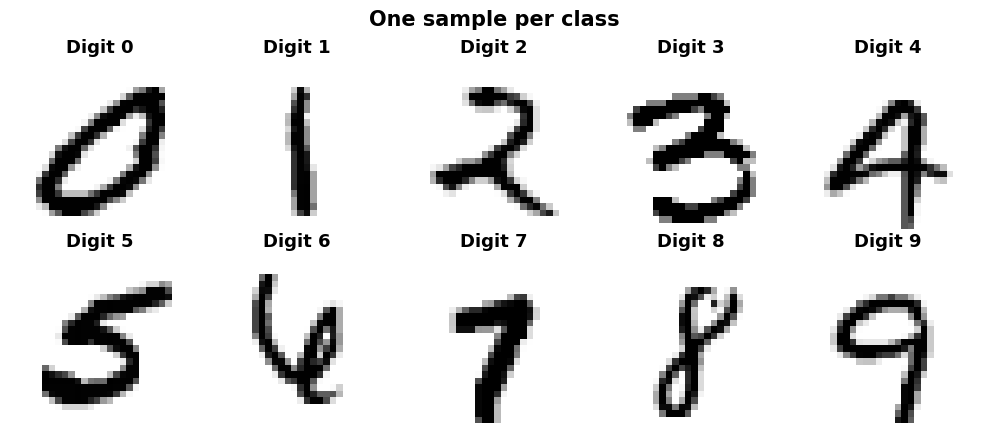

In [4]:
# 1. Load the MNIST dataset via OpenML (70,000 samples of 784 features)
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist['data'], mnist['target'].astype(np.int8)

# 2. Verify dimensions
print(f"Full dataset: X = {X.shape}, y = {y.shape}")

# 3. Normalize pixel values to [0, 1]
X = X.astype('float32') / 255.0

# 4. Split into 80% training and 20% validation
#    Stratified sampling to preserve class distribution
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Display the shape of the resulting sets
print("Training set: X_train =", X_train.shape, ", y_train =", y_train.shape)
print("Validation set: X_val   =", X_val.shape,   ", y_val   =", y_val.shape)

# 6. Plot one example of each digit
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digit, ax in enumerate(axes.flatten()):
    ax.imshow(X_train[y_train == digit][0].reshape(28, 28), cmap='gray_r')
    ax.set_title(f"Digit {digit}")
    ax.axis('off')
fig.suptitle("One sample per class", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 2. The model

### Encoding the labels
The network outputs 10 probabilities, so each label $y$ is transformed into a **one-hot vector** (for example $3 \to [0,0,0,1,0,0,0,0,0,0]$).

In [6]:
def one_hot_encode(y, num_classes=10): # Transforms a digit into a binary vector
    y = np.asarray(y).flatten()
    n = y.shape[0]
    Y = np.zeros((n, num_classes), dtype=int)
    Y[np.arange(n), y] = 1
    return Y

In [7]:
Y = one_hot_encode(y, num_classes=10) # Encoding the dataset
Y_val = one_hot_encode(y_val, num_classes=10)
Y_train = one_hot_encode(y_train, num_classes=10)

Y.shape

(70000, 10)

### Parameters
With no hidden layer, the whole network is a single weight matrix $W \in \mathbb{R}^{785 \times 10}$ (784 pixels + 1 bias, for 10 classes).

In [9]:
# Initializing de parameters
W = np.random.rand(784 + 1, 10) * .01

### Activation: softmax
The softmax turns the 10 raw scores into 10 probabilities that sum to 1:

$$\text{softmax}(u)_k = \frac{e^{u_k}}{\sum_j e^{u_j}}$$

We subtract the max before the exponential for numerical stability (it does not change the result).

In [11]:
# Activation function
def soft_max(y):
    y_shift = y - np.max(y, axis=1, keepdims=True)
    exps = np.exp(y_shift)

    return exps / np.sum(exps, axis=1, keepdims=True)

### Forward pass
$$f(X) = \text{softmax}\big([X \;|\; 1]\, W\big)$$

where $[X \,|\, 1]$ is $X$ with a column of ones added for the bias.

In [13]:
# Neural Network Without Hidden Layers
def f(X):
    ones_column = np.ones((X.shape[0], 1), dtype=X.dtype)
    X_with_bias = np.append(X, ones_column, axis=1)
    
    return soft_max(X_with_bias @ W)

f(X).shape

(70000, 10)

### Loss: cross-entropy
$$L(W) = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{10} Y_{ik} \, \log f(X)_{ik}$$

It is small when the network gives a high probability to the correct digit. The `1e-15` avoids $\log(0)$.

In [15]:
# Cross-Entropy Loss
def L(X,Y):
    return -np.mean(np.sum(Y*np.log(f(X)+1e-15), axis=1))

L(X_val,Y_val)

2.3022503317218312

### Gradient
For softmax + cross-entropy, the gradient is very simple:

$$\frac{\partial L}{\partial W} = \frac{1}{N} \, [X \,|\, 1]^T \, \big(f(X) - Y\big)$$

In [17]:
def dE(W,X,Y): # Matrix of partial derivatives of E(W)
    ones_column = np.ones((X.shape[0], 1), dtype=X.dtype)
    X_with_bias = np.append(X, ones_column, axis=1)
    return  X_with_bias.transpose() @ (f(X) - Y) / X.shape[0]

dE(W,X,Y).shape

(785, 10)

### Gradient descent step
$$W \leftarrow W - a \, \frac{\partial L}{\partial W}$$

where $a$ is the learning rate.

In [19]:
def update(W,a,dE): # Update step of the parameter W
    W -= a * dE
    return W

## 3. Training

We repeat the update `max_iteration` times and record the validation loss after each step to see how the network learns.

In [21]:
from IPython.display import clear_output

def training(a, max_iteration): # Training function
    Losses = np.array([])
    Losses_train = np.array([])

    for i in range(max_iteration):
        update(W, a, dE(W,X_train,Y_train))
        Losses = np.append(Losses,L(X_val,Y_val))
        Losses_train = np.append(Losses_train,L(X_train,Y_train))

        # Live plot, refreshed every 2 iterations
        if i % 2 == 0 or i == max_iteration - 1:
            clear_output(wait=True)
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

            ax1.plot(np.arange(Losses_train.size), Losses_train, color=BLUE, linewidth=2.5, label=f'Training loss = {Losses_train[-1]:.3f}')
            ax1.set_title('Training loss')

            ax2.plot(np.arange(Losses.size), Losses, color=ORANGE, linewidth=2.5, label=f'Validation loss = {Losses[-1]:.3f}')
            ax2.set_title('Validation loss')

            for ax in (ax1, ax2):
                ax.set_xlim(0, max_iteration)
                ax.set_xlabel('Iteration')
                ax.legend()
            ax1.set_ylabel('Cross-entropy loss')

            if i == max_iteration - 1:
                fig.suptitle('Loss during training', fontsize=15, fontweight='bold')
            else:
                fig.suptitle(f'Loss during training (iteration {i + 1}/{max_iteration})', fontsize=15, fontweight='bold')
            plt.tight_layout()
            plt.show()

    return W, Losses[-1]

Now we run it. A high learning rate works here because the loss is convex (a single layer), so there are no bad local minima.

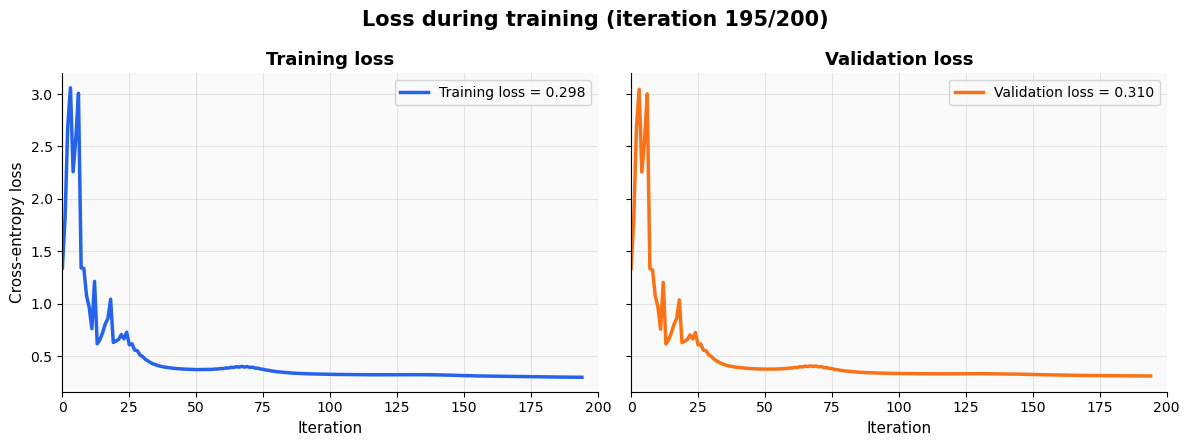

In [ ]:
max_iteration = 200
a = 1.4 #Learning rate

W, Loss = training(a, max_iteration)

print('Cross-Entropy Loss: ', Loss)

## 4. Results

### Accuracy
The loss is useful for training, but what we really want to know is: **how often is the predicted digit the right one?**

In [47]:
pred_train = np.argmax(f(X_train), axis=1)
pred_val = np.argmax(f(X_val), axis=1)

print(f"Training accuracy:   {np.mean(pred_train == y_train):.2%}")
print(f"Validation accuracy: {np.mean(pred_val == y_val):.2%}")

Training accuracy:   91.71%
Validation accuracy: 91.05%


### What did the network learn?
Each column of $W$ (without the bias) has 784 values, one per pixel, so we can display it as a $28 	imes 28$ image.
- **White** pixels: if they are dark in the image, the score of this digit goes **up**.
- **Black** pixels: if they are dark, the score goes **down**.

We can often recognize the shape of the digit in its own template.

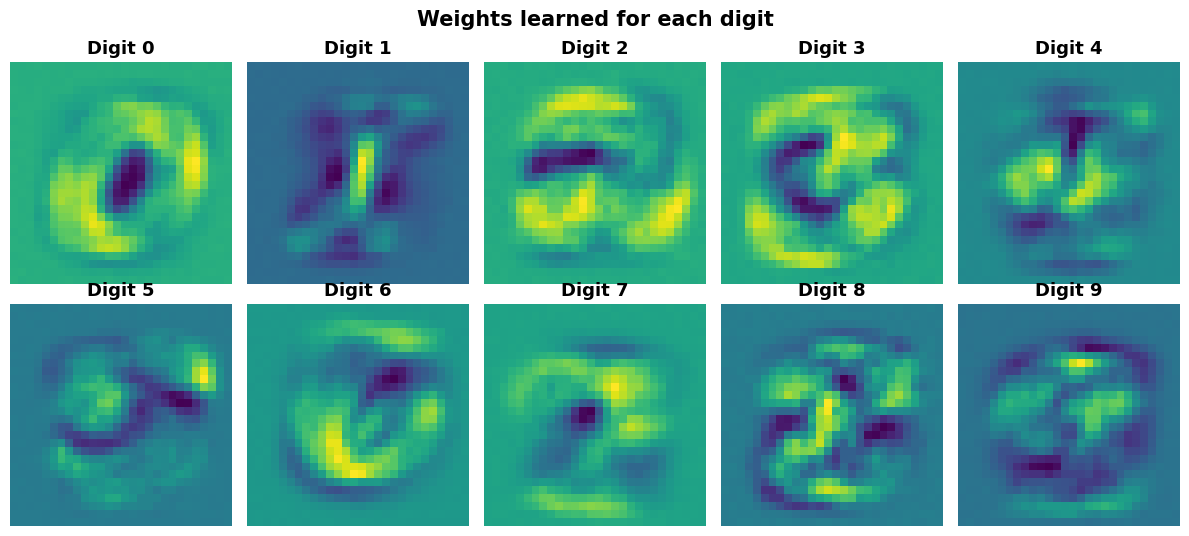

In [60]:
Wt = W[:-1].transpose()
I = Wt.reshape(10,28,28)

fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for idx, ax in enumerate(axes.flatten()) :
    ax.imshow(I[idx])
    ax.set_title(f"Digit {idx}")
    ax.axis('off')
fig.suptitle("Weights learned for each digit", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('image.png', dpi=300, bbox_inches='tight')  # Export the images as 'image.png'
plt.show()

## Bonus: the loss landscape around our minimum

$W$ has $785 \times 10 = 7850$ parameters, so we cannot plot the loss as a function of all of them. Instead we:
1. take the trained weights $W^*$,
2. pick **two random directions** $d_1$ and $d_2$ in the space of $W$ (same shape as $W$),
3. compute the loss on the plane they generate:

$$L(\alpha, \beta) = L\big(W^* + \alpha \, d_1 + \beta \, d_2\big)$$

The point $(0, 0)$ is our trained network. Each direction is rescaled to the same norm as $W^*$, so $\alpha = 1$ means "move by the size of the weights".

In [62]:
np.random.seed(0)

# Two random directions, rescaled to the norm of the trained weights
W_min = W.copy()
d1 = np.random.randn(*W.shape)
d2 = np.random.randn(*W.shape)
d1 = d1 / np.linalg.norm(d1) * np.linalg.norm(W_min)
d2 = d2 / np.linalg.norm(d2) * np.linalg.norm(W_min)

# Loss on a grid of the plane (alpha, beta)
n = 25
alphas = np.linspace(-1, 1, n)
betas = np.linspace(-1, 1, n)
Z = np.zeros((n, n))

for i, alpha in enumerate(alphas):
    for j, beta in enumerate(betas):
        W[:] = W_min + alpha * d1 + beta * d2   # f and L use the global W
        Z[j, i] = L(X_val, Y_val)

W[:] = W_min   # Put back the trained weights
loss_min = L(X_val, Y_val)
print("Loss at the minimum:", loss_min)

Loss at the minimum: 0.30925170314258754


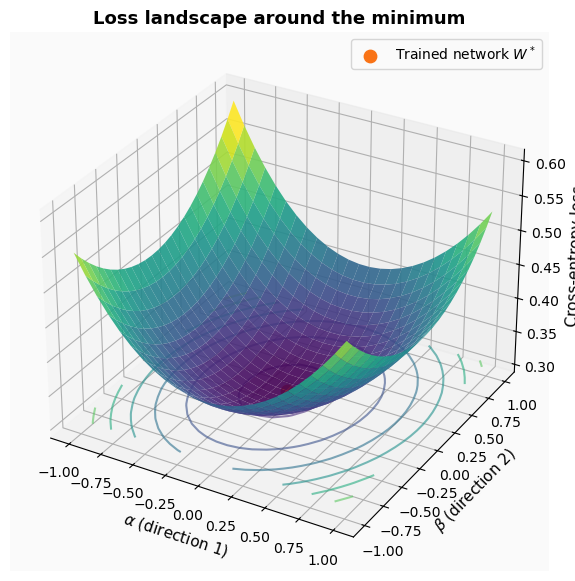

In [63]:
A, B = np.meshgrid(alphas, betas)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(A, B, Z, cmap='viridis', alpha=0.9, edgecolor='none')
ax.contour(A, B, Z, zdir='z', offset=Z.min(), cmap='viridis', alpha=0.6)  # Contour lines on the floor
ax.scatter(0, 0, loss_min, color=ORANGE, s=80, label='Trained network $W^*$')

ax.set_title('Loss landscape around the minimum')
ax.set_xlabel(r'$\alpha$ (direction 1)')
ax.set_ylabel(r'$\beta$ (direction 2)')
ax.set_zlabel('Cross-entropy loss')
ax.view_init(elev=30, azim=-60)
ax.legend()
plt.savefig('loss_landscape.png', dpi=300, bbox_inches='tight')
plt.show()

We see a smooth **bowl** with our network at the bottom. This is expected: the cross-entropy of a network with no hidden layer is a **convex** function of $W$, so there is only one minimum and no trap for the gradient descent. Two random directions in 7850 dimensions are almost perpendicular, so this plane is a typical slice of the landscape.

## Conclusion
- A network with **no hidden layer** is already able to recognize most digits, and its weights are easy to interpret: each digit has a template that looks like the digit itself.
- But it can only learn a **linear** separation between the classes, so its accuracy is limited.
- Its loss is convex, so the gradient descent always goes to the same minimum, as the landscape of the bonus shows.